In [1]:
# Conecta o Colab ao seu Google Drive, para poder ler arquivos de lá
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ==============================
# BLOCO 1 — LEITURA E TRATAMENTO
# ==============================
# Lê a planilha Excel e deixa os dados limpos e prontos para uso

import pandas as pd
import numpy as np
import re

# Caminho do arquivo Excel
arquivo = "/content/drive/MyDrive/Compilação dados quimicos PMP_S_EDFsimp.xlsx"

# Aba que vamos usar na atividade
aba = "EDF dados gerais"

# Leitura da planilha
df = pd.read_excel(arquivo, sheet_name=aba)

print("Dimensão original:", df.shape)
print("Colunas originais:")
print(df.columns.tolist())


# ------------------------------
# 1. Remover colunas vazias ou sem nome
# ------------------------------
df = df.dropna(axis=1, how="all")
df = df.loc[:, ~df.columns.astype(str).str.contains("^Unnamed", case=False, regex=True)]


# ------------------------------
# 2. Função para limpar números
#    Serve para valores como:
#    "< 13", "6965 829", "756 625", "3,5"
# ------------------------------
# def cria uma função reutilizável; ela recebe um valor e devolve a versão numérica dele
def limpar_numero(valor):
    # se já estiver vazio, mantém vazio
    if pd.isna(valor):
        return np.nan

    # se já for número, não mexe
    if isinstance(valor, (int, float, np.integer, np.floating)):
        return valor

    # a partir daqui o valor é texto: tira espaços das pontas
    valor = str(valor).strip()
    # troca vírgula decimal por ponto, e remove os sinais < >
    valor = valor.replace(",", ".")
    valor = valor.replace("<", "")
    valor = valor.replace(">", "")

    # Remove espaços internos, útil para coordenadas como "6965 829"
    valor = re.sub(r"\s+", "", valor)

    # Mantém apenas números, ponto decimal e sinal negativo
    valor = re.sub(r"[^0-9.\-]", "", valor)

    # se não sobrou nada aproveitável, devolve vazio
    if valor in ["", ".", "-", "--"]:
        return np.nan

    # converte o texto limpo para número de verdade
    return pd.to_numeric(valor, errors="coerce")


# ------------------------------
# 3. Padronizar colunas categóricas
# ------------------------------
# lista com os nomes das colunas de texto (não numéricas)
colunas_texto = [
    "Sample",
    "Referência",
    "Locality",
    "Petrology",
    "Country rock",
    "ATi/BTi",
    "Magma Type"
]

# para cada coluna de texto, remove espaços extras
for col in colunas_texto:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()
        df[col] = df[col].str.replace(r"\s+", " ", regex=True)


# Padronizar ATi/BTi
# deixa a classificação ATi/BTi sempre escrita do mesmo jeito
if "ATi/BTi" in df.columns:
    df["ATi/BTi"] = df["ATi/BTi"].str.upper()
    df["ATi/BTi"] = df["ATi/BTi"].replace({
        "ATI": "ATi",
        "BTI": "BTi"
    })


# Padronizar alguns magmas-tipo que aparecem com escrita variante
# corrige nomes de magma digitados de forma diferente
if "Magma Type" in df.columns:
    df["Magma Type"] = df["Magma Type"].replace({
        "Urubi/Pitanga": "Urubici/Pitanga",
        "Esmeralda/ Paranapanema": "Esmeralda/Paranapanema"
    })


# ------------------------------
# 4. Converter colunas numéricas
# ------------------------------
# pega todas as colunas que não são de texto (ou seja, são numéricas)
colunas_numericas = [col for col in df.columns if col not in colunas_texto]

# aplica a função de limpeza em cada uma dessas colunas
for col in colunas_numericas:
    df[col] = df[col].apply(limpar_numero)


# ------------------------------
# 5. Criar razões geoquímicas úteis
# ------------------------------
# cria colunas de razão (divisão) entre elementos químicos, se as colunas existirem
if {"Zr", "Y"}.issubset(df.columns):
    df["Zr/Y"] = df["Zr"] / df["Y"]

if {"Nb", "Y"}.issubset(df.columns):
    df["Nb/Y"] = df["Nb"] / df["Y"]

if {"Sr", "Y"}.issubset(df.columns):
    df["Sr/Y"] = df["Sr"] / df["Y"]

if {"TiO2", "SiO2"}.issubset(df.columns):
    df["TiO2/SiO2"] = df["TiO2"] / df["SiO2"]


# ------------------------------
# 6. Separar base com coordenadas válidas
#    Na planilha, Lat e Long estão em coordenadas UTM.
#    Long = eixo X / Easting
#    Lat = eixo Y / Northing
# ------------------------------
# guarda numa tabela à parte só as amostras que têm Lat/Long preenchidos
df_mapa = df.dropna(subset=["Lat", "Long"]).copy()


# ------------------------------
# 7. Resumos rápidos
# ------------------------------
# imprime alguns números de conferência
print("\nDimensão após limpeza:", df.shape)
print("Amostras com coordenadas válidas:", df_mapa.shape[0])

print("\nContagem por ATi/BTi:")
print(df["ATi/BTi"].value_counts(dropna=False))

print("\nContagem por Magma Type:")
print(df["Magma Type"].value_counts(dropna=False))


# salvar a tabela tratada
# salva a tabela limpa em um novo Excel e mostra as 5 primeiras linhas
df.to_excel("EDF_dados_gerais_tratado.xlsx", index=False)
print(df.head())

Dimensão original: (161, 69)
Colunas originais:
['Sample', 'Referência', 'Lat', 'Long', 'Direção (Az)', 'Locality', 'Petrology', 'Country rock', 'ATi/BTi', 'Magma Type', 'Symbol', 'Color', 'SiO2', 'Al2O3', 'Fe2O3t', 'MnO', 'MgO', 'CaO', 'Na2O', 'K2O', 'TiO2', 'P2O5', 'L.O.I.', 'Total', 'Ba', 'Rb', 'Sr', 'Cs', 'Ga', 'Ta', 'Hf', 'Nb', 'Zr', 'Y', 'Pb', 'Th', 'U', 'V', 'Co', 'Cr', 'Ni', 'Unnamed: 41', 'Sc', 'Zn', 'Cu', 'Cl', 'F', 'S', 'La', 'Ce', 'Pr', 'Nd', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Tm', 'Er', 'Yb', 'Lu', '87Sr/86Sr USP', 'Endt', 'TDM', '206/204Pb', '207/204Pb', '208/204Pb', 'Unnamed: 68']

Dimensão após limpeza: (161, 71)
Amostras com coordenadas válidas: 75

Contagem por ATi/BTi:
ATi/BTi
ATi    146
BTi     15
Name: count, dtype: Int64

Contagem por Magma Type:
Magma Type
Urubici                   117
Pitanga                    14
Pitanga/Urubici             9
Gramado                     6
Esmeralda                   6
Esmeralda/Paranapanema      3
Paranapanema                

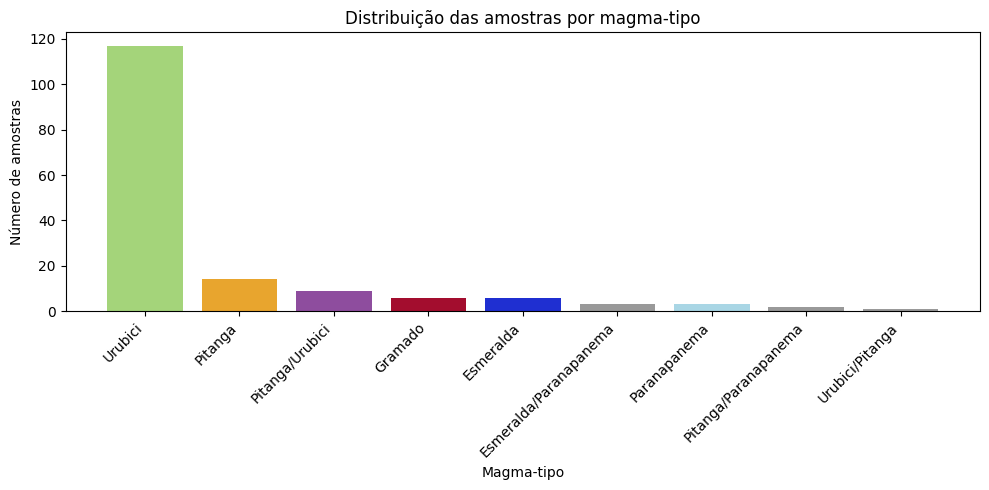

/tmp/ipykernel_2229/1759384663.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(valores, labels=grupos)


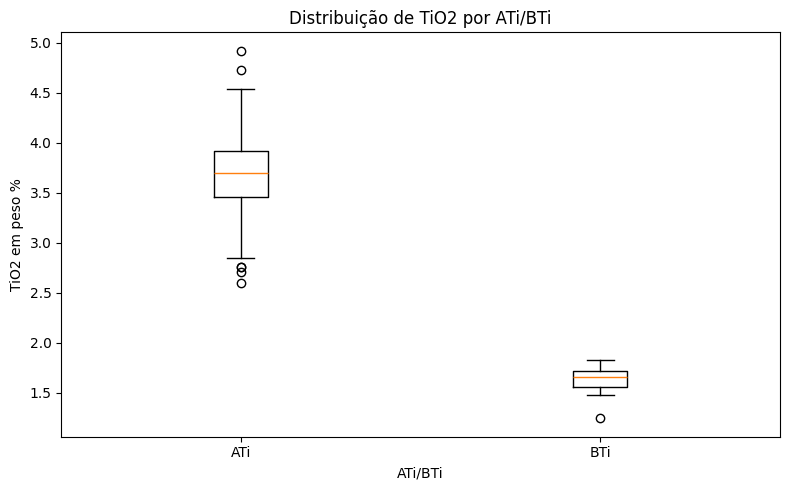

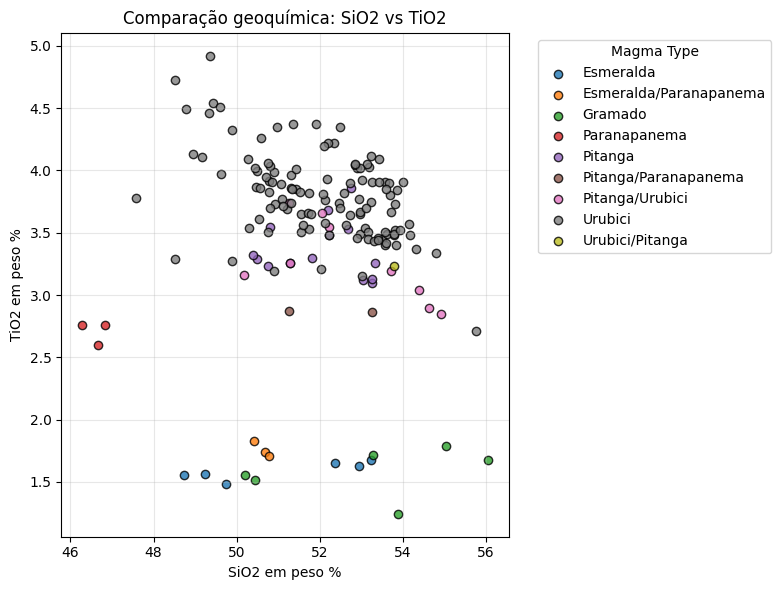

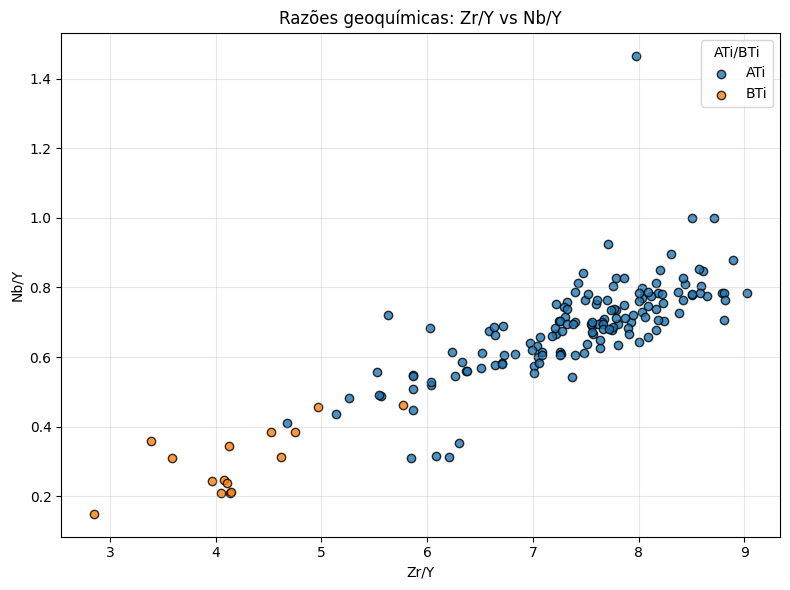

In [3]:
# ==============================
# BLOCO 2 — GRÁFICOS MATPLOTLIB
# ==============================
# Cada gráfico é feito em duas partes: uma função que desenha, e a chamada dela logo depois

import matplotlib.pyplot as plt


# ------------------------------
# GRÁFICO 1 — Distribuição das amostras por magma-tipo
# ------------------------------
# gráfico de barras: quantas amostras existem de cada magma-tipo
def grafico_distribuicao_magma(dados, coluna="Magma Type"):
    cores = {
        "Urubici": "#a4d47a",
        "Pitanga": "#e8a52e",
        "Paranapanema": "#a9d6e5",
        "Esmeralda": "#1f2fd1",
        "Gramado": "#a30d2e",
        "Pitanga/Urubici": "#8e4d9e",
    }

    contagem = dados[coluna].value_counts().sort_values(ascending=False)
    barras_cores = [cores.get(cat, "#999999") for cat in contagem.index]

    plt.figure(figsize=(10, 5))
    plt.bar(contagem.index.astype(str), contagem.values, color=barras_cores)
    plt.title("Distribuição das amostras por magma-tipo")
    plt.xlabel("Magma-tipo")
    plt.ylabel("Número de amostras")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# chama a função acima para desenhar o gráfico de fato
grafico_distribuicao_magma(df, coluna="Magma Type")


# ------------------------------
# GRÁFICO 2 — Distribuição de TiO2 por ATi/BTi
# ------------------------------
# boxplot: compara os valores de uma variável entre os grupos
def grafico_boxplot_geoquimico(dados, variavel="TiO2", grupo="ATi/BTi"):
    dados_plot = dados.dropna(subset=[variavel, grupo]).copy()

    # monta uma lista de valores para cada grupo
    grupos = dados_plot[grupo].unique()
    valores = [dados_plot.loc[dados_plot[grupo] == g, variavel] for g in grupos]

    plt.figure(figsize=(8, 5))
    plt.boxplot(valores, labels=grupos)
    plt.title(f"Distribuição de {variavel} por {grupo}")
    plt.xlabel(grupo)
    plt.ylabel(f"{variavel} em peso %")
    plt.tight_layout()
    plt.show()


grafico_boxplot_geoquimico(df, variavel="TiO2", grupo="ATi/BTi")


# ------------------------------
# GRÁFICO 3 — Comparação geoquímica: SiO2 vs TiO2
# ------------------------------
# gráfico de dispersão comparando duas variáveis, colorido por grupo
def grafico_comparacao_geoquimica(
    dados,
    x="SiO2",
    y="TiO2",
    grupo="Magma Type"
):
    dados_plot = dados.dropna(subset=[x, y, grupo]).copy()

    plt.figure(figsize=(8, 6))

    # desenha os pontos de cada grupo separadamente (cores diferentes)
    for nome_grupo, sub in dados_plot.groupby(grupo):
        plt.scatter(
            sub[x],
            sub[y],
            label=nome_grupo,
            alpha=0.8,
            edgecolor="black"
        )

    plt.title(f"Comparação geoquímica: {x} vs {y}")
    plt.xlabel(f"{x} em peso %")
    plt.ylabel(f"{y} em peso %")
    plt.legend(title=grupo, bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


grafico_comparacao_geoquimica(
    df,
    x="SiO2",
    y="TiO2",
    grupo="Magma Type"
)


# ------------------------------
# GRÁFICO — Razões Zr/Y vs Nb/Y
# bom para comparação entre elementos-traço
# ------------------------------
# mesmo esquema do gráfico anterior, agora com razões geoquímicas
def grafico_razoes_geoquimicas(
    dados,
    x="Zr/Y",
    y="Nb/Y",
    grupo="ATi/BTi"
):
    dados_plot = dados.dropna(subset=[x, y, grupo]).copy()

    plt.figure(figsize=(8, 6))

    for nome_grupo, sub in dados_plot.groupby(grupo):
        plt.scatter(
            sub[x],
            sub[y],
            label=nome_grupo,
            alpha=0.8,
            edgecolor="black"
        )

    plt.title(f"Razões geoquímicas: {x} vs {y}")
    plt.xlabel(x)
    plt.ylabel(y)
    plt.legend(title=grupo)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


grafico_razoes_geoquimicas(
    df,
    x="Zr/Y",
    y="Nb/Y",
    grupo="ATi/BTi"
)

In [4]:
# ==========================================
# BLOCO 3 — MAPA COM VARIAÇÃO GEOQUÍMICA
# COM FUNDO DE SATÉLITE
# ==========================================
# Plota cada amostra na sua posição geográfica, colorida por uma variável química

# "!" executa um comando do sistema (não é Python): instala bibliotecas extras
!pip install geopandas contextily xyzservices -q

import matplotlib.ticker as mticker
import geopandas as gpd
import contextily as cx


# função principal do bloco: desenha o mapa completo
def plotar_mapa_geoquimico(
    dados,
    variavel="TiO2",
    grupo=None,
    rotular_amostras=False,
    coordenada_x="Long",
    coordenada_y="Lat",
    crs_utm="EPSG:32722",
    usar_fundo_satelite=True
):
## Plota as amostras em coordenadas UTM e colore os pontos por uma variável geoquímica.

## variavel: coluna geoquímica usada para colorir os pontos. Ex.: "TiO2", "SiO2", "MgO", "Zr/Y".
## grupo: coluna categórica opcional. Ex.: "ATi/BTi" ou "Magma Type".
## coordenada_x: coluna UTM E.
## coordenada_y: coluna UTM N.
## crs_utm: sistema de coordenadas. Para SC, testar "EPSG:32722" ou "EPSG:31982".

# Conferir se as colunas existem
    # para de rodar com erro claro se faltar alguma coluna necessária
    colunas_necessarias = [coordenada_x, coordenada_y, variavel]

    if grupo is not None:
        colunas_necessarias.append(grupo)

    for col in colunas_necessarias:
        if col not in dados.columns:
            raise ValueError(f"A coluna '{col}' não existe na tabela.")

    # Copiar dados
    dados_mapa = dados.copy()

    # Garantir que coordenadas e variável geoquímica sejam numéricas
    dados_mapa[coordenada_x] = pd.to_numeric(dados_mapa[coordenada_x], errors="coerce")
    dados_mapa[coordenada_y] = pd.to_numeric(dados_mapa[coordenada_y], errors="coerce")
    dados_mapa[variavel] = pd.to_numeric(dados_mapa[variavel], errors="coerce")

    # Remover linhas sem coordenadas ou sem teor geoquímico
    dados_mapa = dados_mapa.dropna(subset=colunas_necessarias).copy()

    if dados_mapa.empty:
        raise ValueError(
            f"Não há dados válidos para plotar. Verifique as colunas {colunas_necessarias}."
        )

    print(f"Número de pontos plotados: {len(dados_mapa)}")

    # Criar GeoDataFrame
    # transforma a tabela em um GeoDataFrame, com um ponto (posição) por amostra
    gdf = gpd.GeoDataFrame(
        dados_mapa,
        geometry=gpd.points_from_xy(
            dados_mapa[coordenada_x],
            dados_mapa[coordenada_y]
        ),
        crs=crs_utm
    )

    # Criar figura
    fig, ax = plt.subplots(figsize=(9, 11))

    # Limites com margem
    # calcula os limites do mapa com uma margenzinha ao redor dos pontos
    xmin, ymin, xmax, ymax = gdf.total_bounds

    margem_x = (xmax - xmin) * 0.08
    margem_y = (ymax - ymin) * 0.08

    ax.set_xlim(xmin - margem_x, xmax + margem_x)
    ax.set_ylim(ymin - margem_y, ymax + margem_y)

    # Fundo de satélite
    # desenha a imagem de satélite por trás dos pontos
    if usar_fundo_satelite:
        cx.add_basemap(
            ax,
            source=cx.providers.Esri.WorldImagery,
            crs=gdf.crs,
            attribution_size=6
        )

    # Plot sem grupo
    # sem grupo: todos os pontos de uma vez, cor contínua conforme a variável
    if grupo is None:
        pontos = ax.scatter(
            gdf[coordenada_x],
            gdf[coordenada_y],
            c=gdf[variavel],
            s=80,
            alpha=0.90,
            edgecolor="black"
        )

        cbar = plt.colorbar(pontos, ax=ax, shrink=0.75)
        cbar.set_label(variavel)

    # Plot com grupo
    # com grupo: um marcador (formato) diferente para cada categoria
    else:
        marcadores = ["o", "s", "^", "D", "P", "X", "*", "v"]

        ultimo_pontos = None

        for i, (nome_grupo, sub) in enumerate(gdf.groupby(grupo)):
            ultimo_pontos = ax.scatter(
                sub[coordenada_x],
                sub[coordenada_y],
                c=sub[variavel],
                s=85,
                alpha=0.90,
                edgecolor="black",
                marker=marcadores[i % len(marcadores)],
                label=nome_grupo
            )

        cbar = plt.colorbar(ultimo_pontos, ax=ax, shrink=0.75)
        cbar.set_label(variavel)

        ax.legend(title=grupo, loc="upper right")

    # Rótulos das amostras
    # se pedido, escreve o nome de cada amostra ao lado do ponto
    if rotular_amostras and "Sample" in gdf.columns:
        for _, linha in gdf.iterrows():
            ax.text(
                linha[coordenada_x],
                linha[coordenada_y],
                linha["Sample"],
                fontsize=7,
                ha="left",
                va="bottom"
            )

    # Título e eixos
    ax.set_title(
        f"Distribuição espacial das amostras — variação de {variavel}",
        fontsize=13
    )

    ax.set_xlabel("Coordenada UTM E")
    ax.set_ylabel("Coordenada UTM N")

    # Coordenadas sem notação científica
    ax.ticklabel_format(style="plain", axis="both", useOffset=False)

    ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.0f}"))
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.0f}"))

    # Coordenadas da esquerda na vertical
    ax.tick_params(axis="y", labelrotation=90)

    # Garantir eixo Y ascendente
    ax.set_ylim(ymin - margem_y, ymax + margem_y)

    # Proporção real
    ax.set_aspect("equal")

    # Grade
    ax.grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()

Número de pontos plotados: 75


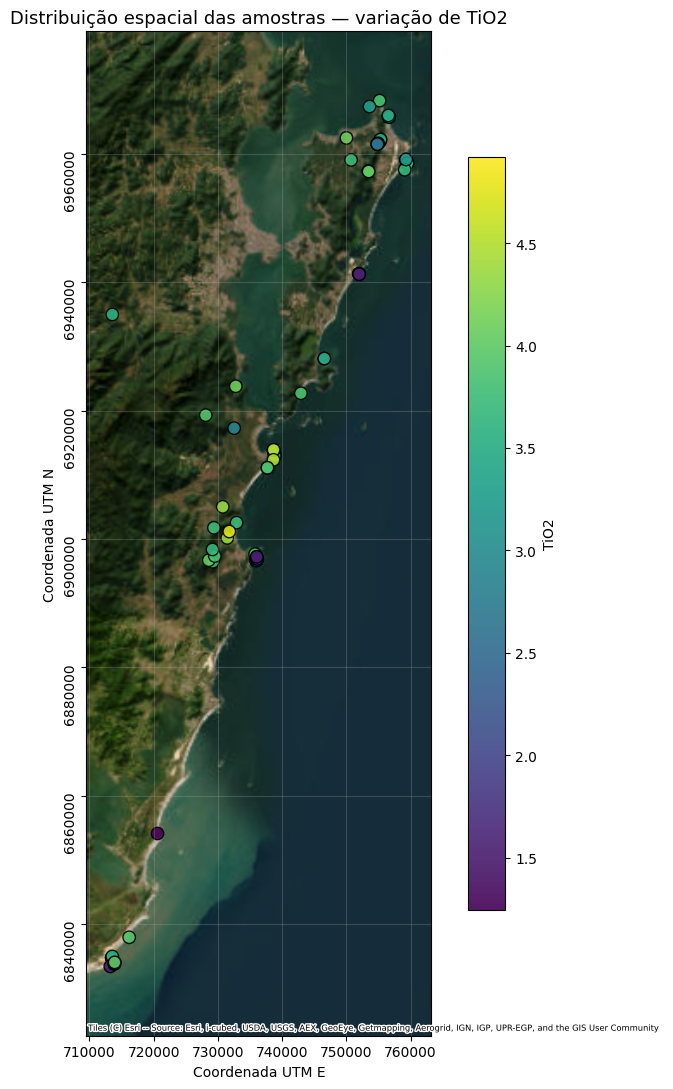

In [5]:
# Exemplo 1 — mapa com variação de TiO2
plotar_mapa_geoquimico(
    df,
    variavel="TiO2",
    grupo=None,
    rotular_amostras=False,
    usar_fundo_satelite=True
)

Número de pontos plotados: 75


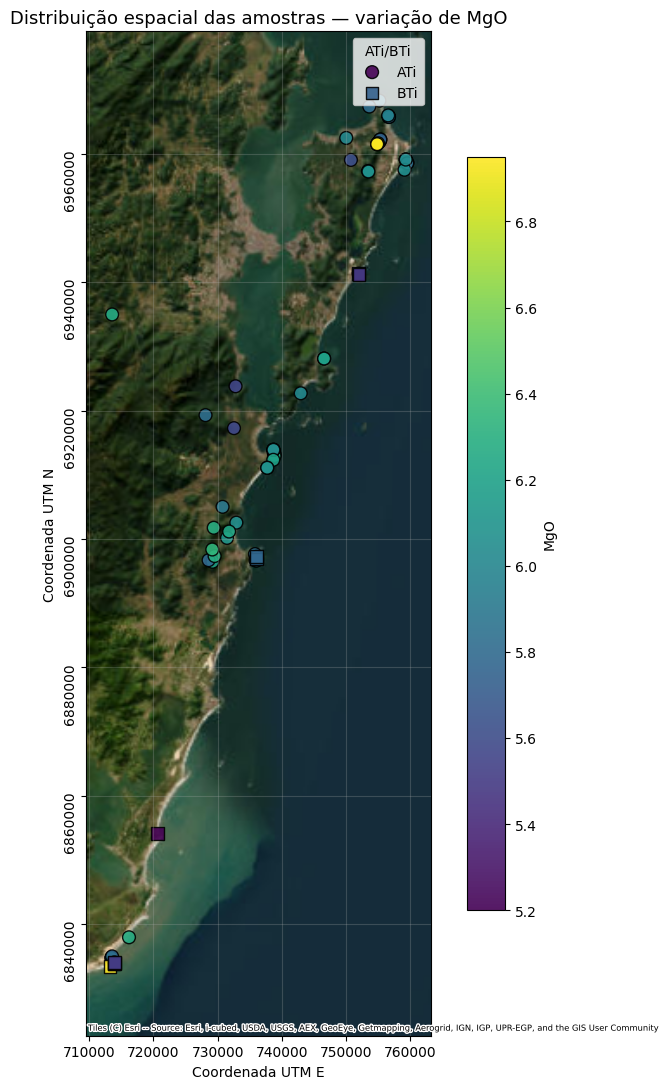

In [6]:
# Exemplo 2 — mapa com variação de MgO, separando ATi/BTi
plotar_mapa_geoquimico(
    df,
    variavel="MgO",
    grupo="ATi/BTi",
    rotular_amostras=False,
    usar_fundo_satelite=True
)

In [7]:
# ======================================================
# BLOCO 4 — DIAGRAMAS BINÁRIOS COM POLÍGONOS ARREDONDADOS
# Campos de literatura no fundo + pontos das amostras
# ======================================================
# Desenha campos conhecidos da literatura + os pontos das amostras por cima

from matplotlib.patches import Polygon
from matplotlib.lines import Line2D


# ------------------------------------------------------
# 1. Suavizar polígonos fechados
# ------------------------------------------------------
# recebe poucos pontos (vértices) e devolve uma curva arredondada passando por eles
def suavizar_poligono(pontos, n_interpolacao=25):

    pontos = np.array(pontos, dtype=float)

    # Fechar o polígono repetindo pontos no início e no fim
    pts = np.vstack([pontos[-2], pontos[-1], pontos, pontos[0], pontos[1]])

    curva = []

    # percorre os pontos calculando a curva suave entre eles
    for i in range(2, len(pts) - 2):
        p0, p1, p2, p3 = pts[i - 1], pts[i], pts[i + 1], pts[i + 2]

        for t in np.linspace(0, 1, n_interpolacao):
            t2 = t * t
            t3 = t2 * t

            ponto = 0.5 * (
                (2 * p1)
                + (-p0 + p2) * t
                + (2*p0 - 5*p1 + 4*p2 - p3) * t2
                + (-p0 + 3*p1 - 3*p2 + p3) * t3
            )

            curva.append(ponto)

    return np.array(curva)

In [8]:
# ------------------------------------------------------
# 2. Campos arredondados — MgO vs TiO2
# ------------------------------------------------------
# Estes pontos são os vértices-base. A função suavizar_poligono()
# transforma isso em campos arredondados.
# Você pode ajustar ponto por ponto se quiser aproximar mais da imagem original.

# dicionário: cada campo geológico tem uma cor, uma posição de rótulo e seus vértices
campos_mgo_tio2_arredondados = {
   "Gramado": {
       "cor": "#f00012",
        "label": (2.90, 1.35),
        "coords": [
            # ponta esquerda
            (2.30, 1.20), (2.45, 1.60), (2.40, 1.95),

            # topo
            (2.90, 1.90), (3.80, 1.85), (4.80, 1.50),
            (5.80, 1.40), (6.80, 1.30), (7.80, 1.20),

            # ponta direita
            (8.70, 0.95), (9.40, 0.85), (9.80, 0.75),

            # base
            (9.50, 0.70), (9.10, 0.73),
            (8.30, 0.79), (7.90, 0.75), (6.70, 0.75),
            (5.50, 1.05), (4.30, 1.30), (3.50, 1.30),
            (2.70, 1.25),
        ]
    },


    "Ribeira": {
        "cor": "#8791d0",
        "label": (3.05, 2.20),
        "coords": [
            (2.45, 2.15), (2.90, 2.30), (3.55, 2.35),
            (4.25, 2.40), (5.10, 2.10), (5.95, 1.95),
            (6.60, 1.70), (6.25, 1.50), (5.35, 1.48),
            (4.45, 1.60), (3.70, 1.85), (3.00, 2.05)
        ]
    },
  "Esmeralda": {
        "cor": "#10962f",
        "label": (7.05, 1.35),
        "coords": [
            (3.30, 2.00), (3.90, 1.70), (4.60, 1.60),
            (5.50, 1.40), (6.40, 1.20), (7.20, 1.15),
            (7.90, 1.15), (7.50, 1.38), (6.60, 1.55),
            (5.60, 1.80), (4.70, 2.00), (3.90, 2.15)
        ]
    },

    "Paranapanema": {
        "cor": "#b9d7f0",
        "label": (6.20, 2.75),
        "coords": [
            (3.35, 3.05), (3.75, 3.15), (4.35, 3.05),
            (5.10, 2.90), (5.60, 2.90), (6.05, 2.55),
            (6.75, 2.25), (7.15, 2.15), (7.00, 2.00),
            (6.30, 1.90), (5.45, 1.92), (4.70, 1.99),
            (4.00, 2.25), (3.45, 2.55)
        ]
    },

    "Pitanga": {
        "cor": "#e6951a",
        "label": (6.05, 3.75),
        "coords": [
            (2.70, 3.00), (3.05, 3.35), (3.65, 3.55),
            (4.25, 3.85), (4.70, 4.05), (5.25, 4.00),
            (5.85, 3.95), (6.25, 3.65), (6.30, 3.20),
            (6.00, 2.95), (5.35, 2.85), (4.55, 2.85),
            (3.85, 3.00), (3.20, 3.10)
        ]
    },

    "Urubici": {
        "cor": "#b4d900",
        "label": (4.55, 4.20),
        "coords": [
            (3.75, 3.50), (3.90, 3.95), (4.20, 4.35),
            (4.55, 4.55), (4.95, 4.40), (5.25, 4.05),
            (5.50, 3.65), (5.55, 3.25), (5.20, 3.15),
            (4.75, 3.18), (4.25, 3.28), (3.90, 3.35)
        ]
    }
}

In [9]:
# ------------------------------------------------------
# 3. Desenhar campos arredondados
# ------------------------------------------------------
# percorre o dicionário de campos e desenha cada um como uma área colorida
def desenhar_campos_arredondados(
    ax,
    campos,
    alpha=0.72,
    mostrar_labels=True,
    n_interpolacao=20
):
    for nome, info in campos.items():
        coords_suaves = suavizar_poligono(
            info["coords"],
            n_interpolacao=n_interpolacao
        )

        poligono = Polygon(
            coords_suaves,
            closed=True,
            facecolor=info["cor"],
            edgecolor="black",
            linewidth=1.4,
            alpha=alpha,
            zorder=1
        )

        ax.add_patch(poligono)

        # escreve o nome do campo na posição indicada
        if mostrar_labels:
            ax.text(
                info["label"][0],
                info["label"][1],
                nome,
                fontsize=13,
                fontweight="bold",
                ha="center",
                va="center",
                zorder=3
            )

In [10]:
# ------------------------------------------------------
# 4. Estilo dos pontos
# ------------------------------------------------------
# decide o marcador e a cor do ponto de uma amostra, conforme ATi/BTi e Petrology
def obter_estilo_ponto(linha):
    ati_bti = str(linha.get("ATi/BTi", "")).strip()
    petrology = str(linha.get("Petrology", "")).lower()

    # quadrado para soleira/sill, triângulo para os demais
    if "sill" in petrology or "soleira" in petrology:
        marcador = "s"
    else:
        marcador = "^"

    # cor conforme a classificação ATi/BTi
    if ati_bti == "ATi":
        cor = "limegreen"
    elif ati_bti == "BTi":
        cor = "blue"
    else:
        cor = "gray"

    facecolor = "none" if marcador == "^" else cor

    # devolve os três valores calculados
    return marcador, cor, facecolor

In [11]:
# ------------------------------------------------------
# 5. Plotar MgO vs TiO2 com campos arredondados
# ------------------------------------------------------
# junta os campos e os pontos das amostras no gráfico final MgO x TiO2
def plotar_mgo_tio2_com_campos_arredondados(
    dados,
    campos,
    x="MgO",
    y="TiO2",
    xlim=(2, 10),
    ylim=(0.5, 4.8),
    mostrar_pontos=True,
    mostrar_labels_campos=True,
    linha_diagonal=True
):
    dados_plot = dados.copy()

    for col in [x, y]:
        dados_plot[col] = pd.to_numeric(dados_plot[col], errors="coerce")

    dados_plot = dados_plot.dropna(subset=[x, y]).copy()

    fig, ax = plt.subplots(figsize=(8, 8))

    # Campos arredondados no fundo
    desenhar_campos_arredondados(
        ax=ax,
        campos=campos,
        alpha=0.72,
        mostrar_labels=mostrar_labels_campos,
        n_interpolacao=25
    )

    # Linha diagonal Baixo-Ti / Alto-Ti
    if linha_diagonal:
        ax.plot(
            [2, 10],
            [2.75, 0.70],
            color="black",
            linestyle="--",
            linewidth=1.8,
            zorder=2
        )

    # Pontos das amostras por cima
    # desenha cada amostra com o marcador/cor definidos por obter_estilo_ponto
    if mostrar_pontos:
        for _, linha in dados_plot.iterrows():
            marcador, cor, facecolor = obter_estilo_ponto(linha)

            ax.scatter(
                linha[x],
                linha[y],
                marker=marcador,
                s=75,
                facecolors=facecolor,
                edgecolors=cor,
                linewidths=1.6,
                alpha=0.85,
                zorder=5
            )

    # Textos Baixo-Ti e Alto-Ti
    ax.text(
        2.25, 0.90,
        "Baixo - Ti",
        fontsize=14,
        fontweight="bold"
    )

    ax.text(
    8.2, 3.9,
    "Alto - Ti",
    fontsize=14,
    fontweight="bold",
    ha="right"
)

    # Legenda dos pontos
    # legenda montada manualmente com símbolos (Line2D)
    legenda = [
        Line2D([0], [0], marker="^", color="none",
               markeredgecolor="limegreen", markerfacecolor="none",
               markersize=9, label="Dique ATi"),

        Line2D([0], [0], marker="s", color="none",
               markeredgecolor="limegreen", markerfacecolor="limegreen",
               markersize=9, label="Soleira ATi"),

        Line2D([0], [0], marker="^", color="none",
               markeredgecolor="blue", markerfacecolor="none",
               markersize=9, label="Dique BTi"),

        Line2D([0], [0], marker="s", color="none",
               markeredgecolor="blue", markerfacecolor="blue",
               markersize=9, label="Soleira BTi")
    ]

    ax.legend(
        handles=legenda,
        loc="upper right",
        frameon=True,
        fontsize=9
    )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    ax.set_xlabel("MgO (% em peso)", fontsize=13, fontweight="bold")
    ax.set_ylabel("TiO₂ (% em peso)", fontsize=13, fontweight="bold")

    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_linewidth(1.8)

    ax.tick_params(axis="both", labelsize=11, width=1.5)

    plt.tight_layout()
    plt.show()

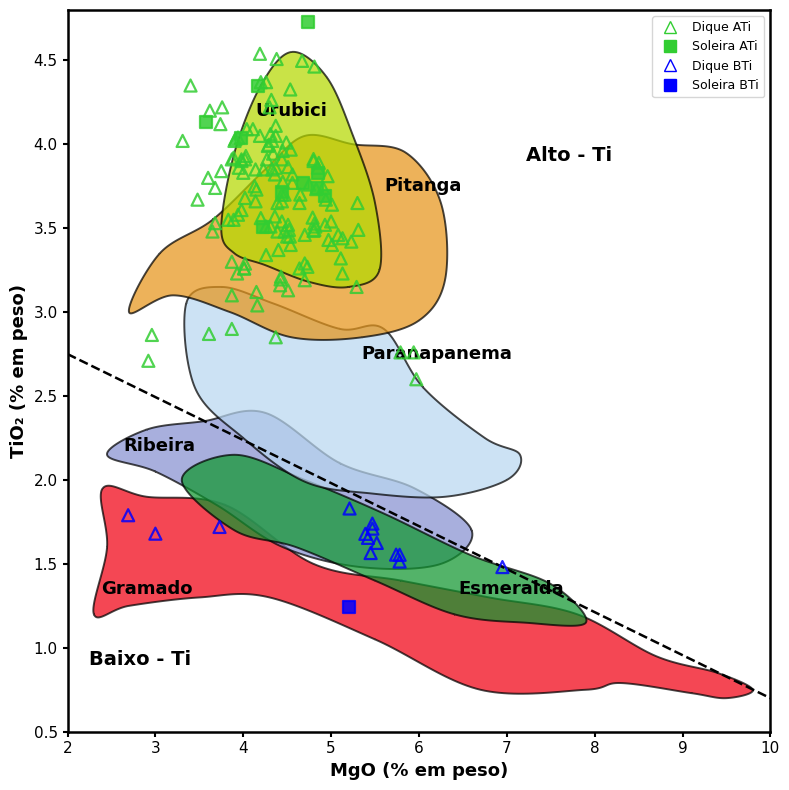

In [12]:
# gera o gráfico final MgO vs TiO2 usando os campos definidos acima
plotar_mgo_tio2_com_campos_arredondados(
    dados=df,
    campos=campos_mgo_tio2_arredondados,
    mostrar_pontos=True,
    mostrar_labels_campos=True,
    linha_diagonal=True
)

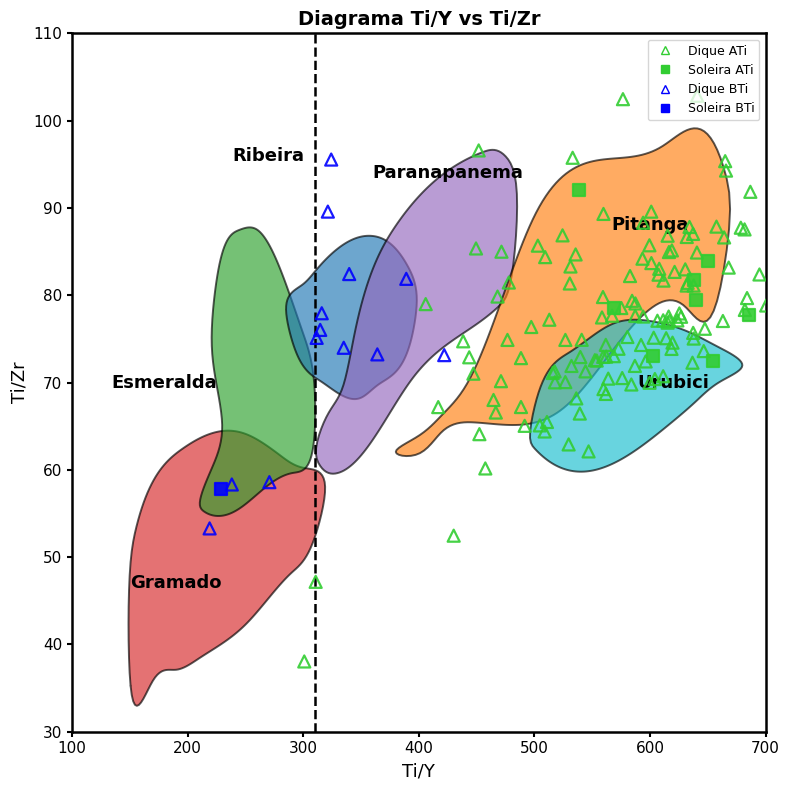

In [13]:
# ======================================================
# BLOCO 5 — DIAGRAMA Ti/Y vs Ti/Zr
# (mesma ideia do Bloco 4, com outra técnica de suavização e outras razões)
# ======================================================
from scipy.interpolate import splprep, splev


# calcula as razões geoquímicas Ti/Y e Ti/Zr necessárias para o diagrama
def preparar_razoes_para_diagramas(dados):
    dados = dados.copy()

    colunas_quimicas = ["Ti", "TiO2", "Y", "Zr", "MgO"]

    for col in colunas_quimicas:
        if col in dados.columns:
            dados[col] = pd.to_numeric(dados[col], errors="coerce")

    # usa Ti direto se existir, senão estima a partir de TiO2
    if "Ti" in dados.columns:
        dados["Ti_ppm"] = dados["Ti"]
    elif "TiO2" in dados.columns:
        dados["Ti_ppm"] = dados["TiO2"] * 5995
    else:
        raise ValueError("A tabela precisa ter a coluna 'Ti' ou 'TiO2'.")

    dados["Ti/Y"] = dados["Ti_ppm"] / dados["Y"]
    dados["Ti/Zr"] = dados["Ti_ppm"] / dados["Zr"]

    return dados


# outra forma de suavizar o polígono, agora usando a biblioteca scipy
def suavizar_poligono(coords, suavidade=8, pontos=200):
    coords = np.array(coords)

    x = np.r_[coords[:, 0], coords[0, 0]]
    y = np.r_[coords[:, 1], coords[0, 1]]

    tck, _ = splprep([x, y], s=suavidade, per=True)

    u_novo = np.linspace(0, 1, pontos)
    x_suave, y_suave = splev(u_novo, tck)

    return np.column_stack([x_suave, y_suave])


# campos de literatura para este novo diagrama (mesma estrutura do Bloco 4)
campos_tiy_tizr = {
    "Gramado": {"cor": "#d62728",
        "coords": [
            (150,35),(170,36),(190,37),(210,38.5),(230,40),
            (250,42.5),(270,45),(290,48.5),(310,52),(315,55),
            (320,58),(300,60),(280,62),(250,63.5),(220,65),
            (195,62),(170,58),(155,54),(150,50),(150,42)
        ],
        "label": (190,47)
    },

    "Esmeralda": {"cor": "#2ca02c",
        "coords": [
            (210,56),(220,60),(230,65),(225,70),(220,75),
            (225,80),(230,86),(245,87),(260,88),(275,84),
            (290,80),(300,75),(310,70),(310,66),(310,63),
            (290,60),(270,58),(250,56),(230,55),(215,55)
        ],
        "label": (180,70)
    },

    "Ribeira": {"cor": "#1f77b4",
        "coords": [
            (285,79),(300,81),(310,83),(330,85),(345,87),
            (360,86.5),(375,86),(390,83),(400,80),(395,76),
            (385,72),(365,70),(350,68),(330,69),(315,70),
            (300,72),(290,75),(285,77)
        ],
        "label": (270,96)
    },

    "Paranapanema": {"cor": "#9467bd",
        "coords": [
            (310,62),(320,66),(335,70),(345,75),(350,80),
            (365,84),(380,88),(405,92),(430,95),(455,96),
            (475,96),(485,92),(485,88),(480,83),(470,78),
            (445,76),(420,75),(395,70),(370,65),(350,62),
            (330,60),(315,60)
        ],
        "label": (425,94)
    },

    "Pitanga": {"cor": "#ff7f0e",
        "coords": [
            (380,62),(400,64),(420,66),(440,70),(460,75),
            (480,82),(500,90),(535,94),(570,96),(610,97),
            (650,98),(665,95),(670,90),(665,85),(660,80),
            (630,79),(600,78),(570,74),(540,70),(525,67),
            (510,65),(480,65),(450,66),(420,64),(400,62)
        ],
        "label": (600,88)
    },

    "Urubici": {"cor": "#17becf",
        "coords": [
            (500,61),(520,60.5),(540,60),(565,61),(590,62),
            (615,65),(640,68),(660,70),(680,72),(660,74),
            (630,76),(600,77),(570,77),(550,75),(530,74),
            (515,71),(500,68),(495,64)
        ],
        "label": (620,70)
    }
}


# desenha os campos de literatura, usando a nova função de suavização
def desenhar_campos_literatura(ax, campos, alpha=0.65):
    for nome, info in campos.items():

        coords_suave = suavizar_poligono(info["coords"], suavidade=8)

        poligono = Polygon(
            coords_suave,
            closed=True,
            facecolor=info["cor"],
            edgecolor="black",
            linewidth=1.4,
            alpha=alpha,
            zorder=1,
            joinstyle="round"
        )

        ax.add_patch(poligono)

        ax.text(
            info["label"][0],
            info["label"][1],
            nome,
            fontsize=13,
            fontweight="bold",
            ha="center",
            va="center",
            zorder=3
        )


# igual à função do Bloco 4, mas devolve só marcador e cor
def obter_estilo_ponto(linha):
    ati_bti = str(linha.get("ATi/BTi", "")).strip()
    petrology = str(linha.get("Petrology", "")).lower()

    marcador = "s" if "sill" in petrology or "soleira" in petrology else "^"

    if ati_bti == "ATi":
        cor = "limegreen"
    elif ati_bti == "BTi":
        cor = "blue"
    else:
        cor = "gray"

    return marcador, cor


# ---- EXECUÇÃO ----
# a partir daqui o código roda de fato e gera o gráfico

# calcula Ti/Y e Ti/Zr e atualiza a tabela df
df = preparar_razoes_para_diagramas(df)

fig, ax = plt.subplots(figsize=(8, 8))

desenhar_campos_literatura(ax, campos_tiy_tizr)

ax.axvline(310, color="black", linestyle="--", linewidth=1.8)

# desenha o ponto de cada amostra
for _, linha in df.iterrows():
    marcador, cor = obter_estilo_ponto(linha)
    facecolor = "none" if marcador == "^" else cor

    ax.scatter(
        linha["Ti/Y"],
        linha["Ti/Zr"],
        marker=marcador,
        s=75,
        facecolors=facecolor,
        edgecolors=cor,
        linewidths=1.6,
        alpha=0.9,
        zorder=5
    )

# legenda manual, mesma lógica do Bloco 4
legenda = [
    Line2D([0],[0],marker="^",color="none",
           markeredgecolor="limegreen",
           markerfacecolor="none",label="Dique ATi"),
    Line2D([0],[0],marker="s",color="none",
           markeredgecolor="limegreen",
           markerfacecolor="limegreen",label="Soleira ATi"),
    Line2D([0],[0],marker="^",color="none",
           markeredgecolor="blue",
           markerfacecolor="none",label="Dique BTi"),
    Line2D([0],[0],marker="s",color="none",
           markeredgecolor="blue",
           markerfacecolor="blue",label="Soleira BTi"),
]

ax.legend(handles=legenda, loc="upper right", fontsize=9)

ax.set_title("Diagrama Ti/Y vs Ti/Zr", fontsize=14, fontweight="bold")
ax.set_xlabel("Ti/Y", fontsize=13)
ax.set_ylabel("Ti/Zr", fontsize=13)

ax.set_xlim(100, 700)
ax.set_ylim(30, 110)

for spine in ax.spines.values():
    spine.set_linewidth(1.8)

ax.tick_params(axis="both", labelsize=11, width=1.5)

plt.tight_layout()
plt.show()